## Regresion: BIKE SHARING

Utilizaremos el dataset de la Universidad de California en Irvine (UCI): Bike Sharing Dataset.
- Problema: regresión supervisada.
- Variable objetivo: cnt, cantidad total de alquileres.
- Unidad de análisis: una hora de operación.
- Objetivo: predecir la demanda de bicicletas a partir de variables temporales y ambientales.

El conjunto original contiene datos de alquileres de bicicletas de Washington D. C. durante 2011 y 2012. Incluye información sobre fechas, estaciones, temperatura, humedad, viento y clima.

2. Variables que utilizaremos
Variable	Descripción	Tipo
cnt	Cantidad total de alquileres	Objetivo
hr	Hora del día (0–23)	Categórica
season	Estación del año	Categórica
mnth	Mes	Categórica
weekday	Día de la semana	Categórica
workingday	Día laborable	Binaria
weathersit	Categoría del clima	Categórica
temp	Temperatura normalizada	Numérica
hum	Humedad normalizada	Numérica
windspeed	Velocidad del viento normalizada	Numérica

Importante: no incluiremos casual ni registered como variables predictoras, porque cnt es la suma de ambas. Utilizarlas produciría fuga de información (data leakage): estaríamos usando datos que revelan directamente el resultado que queremos predecir. La estructura de las variables está documentada en UCI. 


Dimensiones: (17379, 17)

Primeros registros:
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  

Información del dataset:
<class 'pandas.DataFrame'>


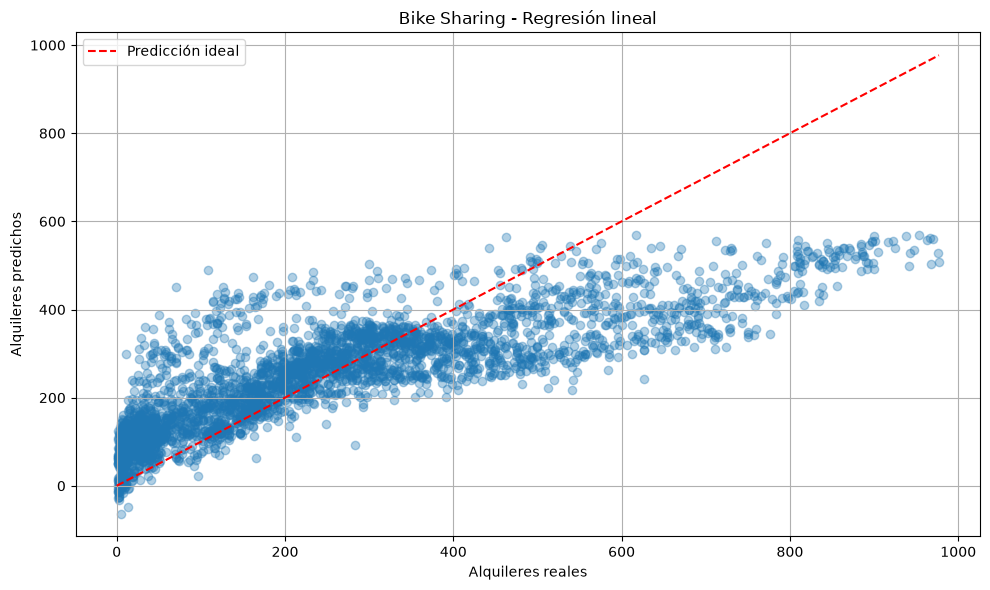


--- Predicción de demanda ---
Alquileres estimados: 459


: 

In [ ]:
import io
import urllib.request
import zipfile

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Descargar y cargar el dataset
# --------------------------------------------------

url = (
    "https://archive.ics.uci.edu/static/public/"
    "275/bike+sharing+dataset.zip"
)

with urllib.request.urlopen(url) as response:
    contenido_zip = response.read()

with zipfile.ZipFile(io.BytesIO(contenido_zip)) as archivo:
    with archivo.open("hour.csv") as archivo_csv:
        df = pd.read_csv(archivo_csv)

print("Dimensiones:", df.shape)
print("\nPrimeros registros:")
print(df.head())

print("\nInformación del dataset:")
df.info()

print("\nValores faltantes:")
print(df.isnull().sum().sum())


# --------------------------------------------------
# 2. Seleccionar variables
# --------------------------------------------------

# Variables categóricas:
# Aunque algunas son números, representan categorías.
categoricas = [
    "season",
    "mnth",
    "hr",
    "weekday",
    "weathersit"
]

# Variables numéricas y binarias.
numericas = [
    "yr",
    "holiday",
    "workingday",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

# Variables predictoras.
X = df[numericas + categoricas]

# Cantidad total de bicicletas alquiladas.
y = df["cnt"]


# --------------------------------------------------
# 3. Separación cronológica entrenamiento/prueba
# --------------------------------------------------

# Ordenar por fecha y hora.
df["dteday"] = pd.to_datetime(df["dteday"])

orden = df.sort_values(["dteday", "hr"]).index

X = X.loc[orden].reset_index(drop=True)
y = y.loc[orden].reset_index(drop=True)

# Primer 80% para entrenamiento, último 20% para prueba.
punto_corte = int(len(X) * 0.80)

X_train = X.iloc[:punto_corte]
X_test = X.iloc[punto_corte:]

y_train = y.iloc[:punto_corte]
y_test = y.iloc[punto_corte:]

print("\nRegistros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))


# --------------------------------------------------
# 4. Preprocesamiento
# --------------------------------------------------

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            categoricas
        ),
        (
            "numericas",
            "passthrough",
            numericas
        )
    ]
)


# --------------------------------------------------
# 5. Crear y entrenar el modelo
# --------------------------------------------------

modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("regresion", LinearRegression())
    ]
)

modelo.fit(X_train, y_train)


# --------------------------------------------------
# 6. Generar predicciones
# --------------------------------------------------

y_pred = modelo.predict(X_test)


# --------------------------------------------------
# 7. Evaluar el modelo
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5

r2 = r2_score(y_test, y_pred)

print("\n--- Métricas del modelo ---")
print(f"MAE:  {mae:.2f} bicicletas")
print(f"RMSE: {rmse:.2f} bicicletas")
print(f"R²:   {r2:.4f}")


# --------------------------------------------------
# 8. Graficar valores reales y predichos
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35
)

limite = max(y_test.max(), y_pred.max())

plt.plot(
    [0, limite],
    [0, limite],
    "r--",
    label="Predicción ideal"
)

plt.xlabel("Alquileres reales")
plt.ylabel("Alquileres predichos")
plt.title("Bike Sharing - Regresión lineal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 9. Predecir la demanda para una hora nueva
# --------------------------------------------------

nuevo_registro = pd.DataFrame([{
    "season": 2,
    "mnth": 5,
    "hr": 8,
    "weekday": 2,
    "weathersit": 1,
    "yr": 1,
    "holiday": 0,
    "workingday": 1,
    "temp": 0.60,
    "atemp": 0.58,
    "hum": 0.50,
    "windspeed": 0.20
}])

prediccion = modelo.predict(nuevo_registro)[0]

# La cantidad de alquileres no puede ser negativa.
prediccion_ajustada = max(0, prediccion)

print("\n--- Predicción de demanda ---")
print(f"Alquileres estimados: {prediccion_ajustada:.0f}")


## ¿Cómo interpretar los resultados?

Al ejecutar el programa, obtendrás tres métricas principales. Sus valores exactos dependerán de la ejecución y de la partición de los datos.
Métrica	Interpretación

MAE	Error absoluto medio, expresado en cantidad de bicicletas. Si vale 40, las predicciones se desvían en promedio 40 bicicletas.
RMSE	Error cuadrático medio en raíz; penaliza más los errores grandes. También se expresa en bicicletas.
R²	Mide cuánto de la variabilidad de la demanda explica el modelo. Un valor más cercano a 1 suele indicar mejor ajuste.
El gráfico compara la demanda real con la predicha. Cuanto más cerca estén los puntos de la línea roja, más precisas serán las predicciones.

### Consideraciones importantes
- Las variables temp, atemp, hum y windspeed están normalizadas; no representan directamente grados Celsius, porcentaje de humedad ni velocidad en km/h.
- OneHotEncoder permite tratar horas, meses y estaciones como categorías, sin asumir que sus códigos numéricos representan distancias equivalentes.
- La separación cronológica es más apropiada que una partición aleatoria cuando el objetivo es evaluar predicciones futuras.
- La regresión lineal es un buen modelo de referencia (baseline), pero la demanda puede tener relaciones no lineales con la hora, el clima y los días laborables.

Siguiente experimento recomendado: comparar esta regresión lineal con RandomForestRegressor usando exactamente la misma separación temporal. Esto permitirá comprobar si un modelo basado en árboles captura mejor los patrones de demanda.